# Dos pronósticos causales y Huber sobre las mismas observaciones

**Pregunta:** ¿Qué detección y costo de falsas alarmas ofrecen Ridge y los árboles potenciados por histogramas
ante un cambio de recuperación que conserva el balance instantáneo que impone Huber?

Nivel 3 · Requisitos: lecciones 01–02 y partición de entrenamiento, calibración y prueba. · Lectura: 55 minutos.

## Objetivos

Cerrar un balance y predecir un patrón operativo habitual son tareas distintas. Ajustaremos efectivamente
los predictores de árboles potenciados por histogramas y Ridge multicanal de OreBridge. Inspeccionaremos sus
retardos causales comunes y calibraciones separadas de error normal, y los compararemos con Huber usando datos idénticos.
Un cambio controlado de recuperación conserva el balance y rompe las relaciones habituales entre canales.
Un ejemplo de sesgo de alimentación y un control sano mostrarán el intercambio entre perturbaciones omitidas
y falsas alarmas. La comparación se limita deliberadamente a tres casos reservados; no busca el mejor detector.

## Preparación

Trabaja en una copia de OreBridge con el entorno de notebooks activo. Los métodos computacionales están en
`data-pipeline/pipeline`; se necesita el repositorio y no se presupone una distribución OreBridge en PyPI.
Instala estas dependencias numéricas exactas una vez, fuera de este notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Inicia el kernel con `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` y `MKL_NUM_THREADS=1`.
La preparación encuentra el repositorio desde el directorio de trabajo sin imprimir una ruta de la máquina.

In [1]:
# Usar el entorno de CPU con versiones fijas e importar los métodos científicos implementados.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.learning import fit_normal, fit_ridge, lagged, forecast_scores
from pipeline.model.scenarios import generate, channel_specs, conservation_matrix
from pipeline.stages.plant_evaluate import batch_projection, confusion
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Datos

OreBridge es responsable del generador sintético de autoría propia, con licencia MIT, en
`data-pipeline/pipeline/model/scenarios.py`; [repositorio](https://github.com/fsantibanezleal/CAOS_OreBridge).
El contrato de dieciséis canales está también en `data/derived/PL-01/trace.json`. Regeneraremos las semillas
reales 100–107 de entrenamiento, 200–203 de calibración del pronóstico y 300–307 de calibración separada del
estado. La semilla de prueba 1000 queda fuera de todo ajuste y cálculo de umbrales. El archivo
`data/derived/state-model.json` documenta la configuración canónica de HGB. Aquí ajustamos ambas familias sin cargar checkpoints.
Ridge se compara localmente en esta lección; la matriz de 6144 celdas conserva el experimento original de ocho métodos.
Estas secuencias de prueba originales ya son públicas: agregar Ridge es una extensión posterior a la publicación,
no una selección prospectiva con datos nunca examinados. Las pruebas siguen fuera del ajuste y la calibración.

## Método

La [implementación mantenida de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) agrega árboles de regresión secuencialmente para reducir
una pérdida predictiva, agrupando las variables mediante histogramas. OreBridge ajusta un regresor por canal
con un envoltorio multisalida. La configuración efectiva usa 70 iteraciones de potenciación, hasta 12 hojas
por árbol, 64 intervalos, regularización L2 de 1 y semilla 41. Estos valores provienen de `learning.fit_normal`;
no indican optimización para una mina operativa. El objetivo es la siguiente observación y el predictor
nunca recibe la máscara de fallas inyectadas.

El vector de entrada es $(y_{t-1},y_{t-2},y_{t-3},y_{t-4})$ para los dieciséis canales. Todo objetivo
es posterior a todas sus variables predictoras. Los registros se escalan mediante las desviaciones estándar
de entrenamiento, reutilizadas al predecir. Dividir por la desviación estándar no resta la media.
La calibración mide errores absolutos en secuencias normales
separadas; el umbral de cada canal es su percentil empírico superior 99,5. La puntuación es
$s_{tj}=|y_{tj}-\hat y_{tj}|/q_j$: superar uno es una excedencia calibrada, no una probabilidad posterior
de falla. Primero ejecutamos el ajuste e inspeccionamos cuántos ejemplos utilizó.

In [2]:
# Ajustar el estimador numérico publicado con secuencias normales y sin información de prueba.
bundle = fit_normal()
print(f"Filas normales de entrenamiento: {bundle['normal_training_rows']}; "
      f"filas de calibración del pronóstico: {bundle['calibration_rows']}")
print("Semillas de entrenamiento / calibración del pronóstico:", bundle["train_seeds"],
      "/", bundle["calibration_seeds"])
print(f"Umbral de error absoluto de alimentación a flotación: {bundle['threshold'][5]:.6f} t/h")
parameters = bundle["model"].estimators_[0].get_params()
print("Configuración del estimador ajustado:", {k: parameters[k] for k in ["max_iter", "max_leaf_nodes", "max_bins"]})

Filas normales de entrenamiento: 1568; filas de calibración del pronóstico: 784
Semillas de entrenamiento / calibración del pronóstico: [100, 101, 102, 103, 104, 105, 106, 107] / [200, 201, 202, 203]
Umbral de error absoluto de alimentación a flotación: 23.772435 t/h
Configuración del estimador ajustado: {'max_iter': 70, 'max_leaf_nodes': 12, 'max_bins': 64}


Inspeccionamos una matriz de diseño con el constructor de retardos importado. Doscientas observaciones
y cuatro pasos previos producen 196 objetivos y 64 variables predictoras. El primer objetivo corresponde
al segundo cuatro y sus bloques de entrada a los segundos tres, dos, uno y cero. Ese orden importa al buscar
filtración de información: dividir ventanas solapadas al azar puede filtrar duplicados próximos aunque la
API parezca inocua. Aquí secuencias completas con semillas distintas separan ajuste y calibración.

In [3]:
# Mostrar el orden causal de las ventanas antes de evaluar una perturbación reservada.
normal_sequence = generate(seed=100, steps=200)
features, targets = lagged(normal_sequence.observed)
print(f"Matriz de variables predictoras: {features.shape}; matriz objetivo: {targets.shape}")
print("Primera historia de alimentación, reciente a antigua, t/h:", np.round(features[0, [0, 16, 32, 48]], 4))
print(f"Observación posterior de alimentación: {targets[0, 0]:.4f} t/h")

Matriz de variables predictoras: (196, 64); matriz objetivo: (196, 16)
Primera historia de alimentación, reciente a antigua, t/h: [766.6319 748.7098 755.8005 765.56  ]
Observación posterior de alimentación: 765.9217 t/h


Ajustamos ahora un predictor de otra familia con el mismo diseño de retardos. [La regresión Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
usa una matriz lineal de coeficientes y un intercepto para minimizar
$\|\widetilde Y-\widetilde X B-\mathbf{1}b^T\|_F^2+\alpha\|B\|_F^2$.
$B$ tiene 64 filas de variables predictoras y 16 columnas objetivo; scikit-learn guarda su transpuesta en `coef_`.
En esta extensión retrospectiva fijamos $\alpha=1$, intercepto y solución por SVD antes de medir los resultados
de prueba de Ridge. La penalización desalienta coeficientes grandes cuando los
canales retardados están correlacionados. No impone conservación ni convierte coeficientes en aristas causales.

La función importada `fit_ridge` entrena con las mismas ocho semillas normales y calibra errores con las mismas
cuatro semillas separadas de HGB. Reutiliza el escalamiento por desviación estándar de entrenamiento y obtiene
su propio percentil superior 99,5 de error para cada objetivo. Comparamos así una relación lineal regularizada
con árboles por histogramas manteniendo historia, unidades y particiones. El estimador mantenido resuelve la
regresión; este notebook no implementa un algoritmo de ajuste.

In [4]:
# Ajustar la familia lineal regularizada con las mismas semillas normales y su propia calibración de error.
ridge_bundle = fit_ridge(train_seeds=range(100, 108), calibration_seeds=range(200, 204), alpha=1.0)
print(f"Ridge: filas de entrenamiento={ridge_bundle['normal_training_rows']}; "
      f"filas de calibración={ridge_bundle['calibration_rows']}")
print("Matriz de coeficientes, objetivos × variables:", ridge_bundle["model"].coef_.shape)
print("Variables predictoras causales retardadas:", ridge_bundle["model"].n_features_in_)
ridge_parameters = ridge_bundle["model"].get_params()
print("Configuración fija de Ridge:", {k: ridge_parameters[k] for k in ["alpha", "fit_intercept", "solver"]})
print(f"Umbral Ridge de error de alimentación a flotación: {ridge_bundle['threshold'][5]:.6f} t/h")

Ridge: filas de entrenamiento=1568; filas de calibración=784
Matriz de coeficientes, objetivos × variables: (16, 64)
Variables predictoras causales retardadas: 64
Configuración fija de Ridge: {'alpha': 1.0, 'fit_intercept': True, 'solver': 'svd'}
Umbral Ridge de error de alimentación a flotación: 21.892671 t/h


Inspeccionamos la relación lineal ajustada para sólidos del concentrado antes de abrir las pruebas. Los
64 coeficientes se ordenan en cuatro filas de retardo y dieciséis columnas de canal siguiendo `lagged`.
Operan sobre entradas escaladas, por lo que la escala de color es adimensional. Muestran qué utiliza el
predictor normal; su interpretación depende de mantener los demás canales correlacionados en el modelo.

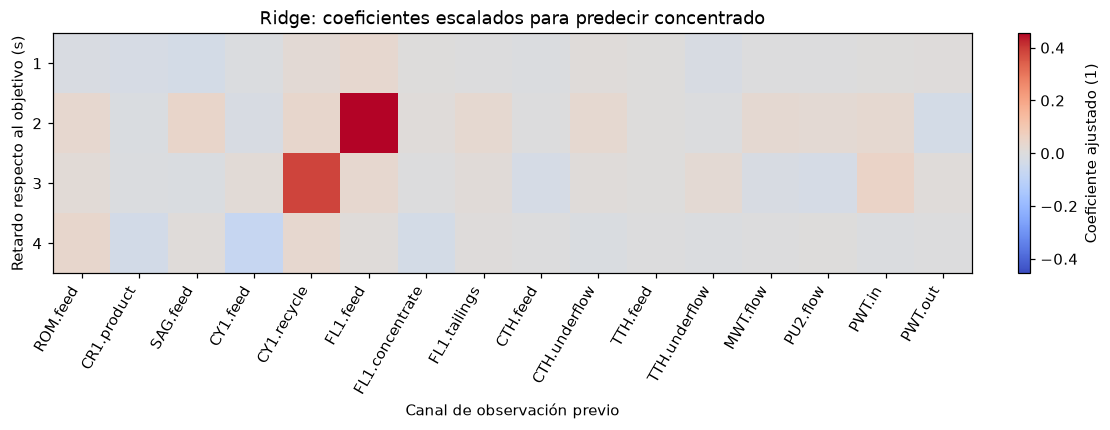

Diferencia declarada de retardo alimentación-concentrado: 2 s
Diferencia declarada de retardo recirculación-concentrado: 3 s


In [5]:
# Leer los coeficientes lineales aprendidos en el diseño real de retardos causales multicanal.
concentrate_weights = ridge_bundle["model"].coef_[6].reshape(4, 16)
color_limit = max(float(np.max(np.abs(concentrate_weights))), 1e-12)
fig, axis = plt.subplots(figsize=(10, 3.8), layout="constrained")
colors = axis.imshow(concentrate_weights, aspect="auto", cmap="coolwarm",
                     vmin=-color_limit, vmax=color_limit)
axis.set_xticks(np.arange(16), [s["id"] for s in specs], rotation=60, ha="right")
axis.set_yticks(np.arange(4), [1, 2, 3, 4])
axis.set(title="Ridge: coeficientes escalados para predecir concentrado", xlabel="Canal de observación previo",
         ylabel="Retardo respecto al objetivo (s)")
fig.colorbar(colors, ax=axis, label="Coeficiente ajustado (1)")
plt.show()
print("Diferencia declarada de retardo alimentación-concentrado:", specs[6]["delay_s"] - specs[5]["delay_s"], "s")
print("Diferencia declarada de retardo recirculación-concentrado:", specs[6]["delay_s"] - specs[4]["delay_s"], "s")

Cada celda de color es un peso de predicción lineal condicionado al resto, no una fracción física de
transferencia. Los retardos y canales comparten información sobre la carga sintética; varios patrones de
coeficientes pueden dar pronósticos similares. Ridge elige una solución penalizada y los signos negativos
o pesos grandes no demuestran causalidad. En este ajuste destacan pesos positivos de alimentación con retardo
dos y recirculación con retardo tres, coincidentes con las diferencias declaradas de transporte de dos y tres
segundos del generador. Es concordancia con una construcción sintética conocida, no una medición independiente
de residencia. La relación lineal
puede extrapolar en una dirección de entrada cambiada. Debemos medir si eso ayuda a detectar o propaga
alertas a canales sanos; la imagen de coeficientes por sí sola no lo decide.

La conciliación de Huber busca un estado compatible con $Ax=0$ y limita la influencia de residuos grandes
([pérdida de Huber](https://doi.org/10.1214/aoms/1177703732)). No recuerda relaciones normales de recuperación más allá de esas ecuaciones.
Para igualar exactamente las entradas, aplicaremos Huber a los mismos vectores del reloj que reciben los
predictores. Calibramos esta convención con semillas normales 300–307: es un experimento identificado como
Huber simultáneo, distinto del balance robusto alineado canónico de la lección 04. Las incertidumbres son
las escalas instrumentales declaradas por el generador. El paquete realiza cada proyección robusta;
la celda solo reúne puntuaciones normales y selecciona sus cuantiles empíricos.

La calibración contempla los residuos habituales de transiciones normales de transporte. No repara una
ecuación errónea ni vuelve identificable una perturbación balanceada. Los tres métodos empiezan en el segundo
catorce para observar exactamente las mismas 146 × 16 entradas de prueba, sin ajustar sus umbrales con ellas.

In [6]:
# Calibrar el residuo simultáneo de Huber sin usar los casos reservados.
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
normal_scores = []
for seed in range(300, 308):
    normal_case = generate(seed=seed)
    scores, _, _ = batch_projection(normal_case.observed[14:], sigma, matrix, robust=True)
    normal_scores.append(scores)
robust_threshold = np.quantile(np.concatenate(normal_scores), 0.995, axis=0, method="higher")
robust_threshold = np.maximum(robust_threshold, 0.1)
print(f"Filas separadas de calibración del estado: {sum(len(x) for x in normal_scores)}")
print(f"Umbral robusto de alimentación a flotación: {robust_threshold[5]:.6f} σ")

Filas separadas de calibración del estado: 1168
Umbral robusto de alimentación a flotación: 6.736266 σ


## Comparación

La familia `engine` del generador modifica el reparto entre concentrado y relaves conservando cada ecuación
afectada. Representa una relación de proceso cambiada o un modelo fijo incompatible, no un sensor cuya falla
esté demostrada. Primero pronosticamos las observaciones reservadas y conservamos predicción, puntuación
residual y etiqueta conocida en variables distintas. Un modelo causal válido puede omitir el comienzo de
un cambio abrupto. Puntuar cada punto afectado, sin extender una alarma a todo el intervalo, permite verlo.

In [7]:
# Ejecutar el predictor causal ajustado con nuevas observaciones y conservar cada error puntual.
changed_relation = generate("engine", seed=1000, severity=2)
forecast_score = forecast_scores(bundle, changed_relation.observed)[14:]
test_features, _ = lagged(changed_relation.observed)
forecast = bundle["model"].predict(test_features / np.tile(bundle["scale"], 4)) * bundle["scale"]
forecast = forecast[14 - bundle["lags"]:]
truth = changed_relation.fault[14:]
forecast_metrics = confusion(forecast_score > 1, truth)
print(f"HGB: VP={forecast_metrics['tp']}, FP={forecast_metrics['fp']}, FN={forecast_metrics['fn']}")
print(f"Sensibilidad: {forecast_metrics['recall']:.6f}; "
      f"tasa de falsos positivos: {forecast_metrics['false_positive_rate']:.6f}")

HGB: VP=291, FP=19, FN=9
Sensibilidad: 0.970000; tasa de falsos positivos: 0.009332


Aplicamos Ridge, ajustado por separado, a las mismas ventanas causales de prueba. Su puntuación se divide
por su propio umbral de error normal, igual que HGB usa el suyo. Conservamos tanto el pronóstico en t/h como
la puntuación: una excedencia normalizada puede ocultar magnitud y dirección de una extrapolación. El caso
de recuperación no modifica ajuste, coeficientes, escala ni umbral.

In [8]:
# Usar las mismas observaciones sin alinear y ventanas causales para la segunda familia ajustada.
ridge_score = forecast_scores(ridge_bundle, changed_relation.observed)[14:]
ridge_inputs = test_features / np.tile(ridge_bundle["scale"], ridge_bundle["lags"])
ridge_forecast = ridge_bundle["model"].predict(ridge_inputs) * ridge_bundle["scale"]
ridge_forecast = ridge_forecast[14 - ridge_bundle["lags"]:]
ridge_metrics = confusion(ridge_score > 1, truth)
print(f"Ridge: VP={ridge_metrics['tp']}, FP={ridge_metrics['fp']}, FN={ridge_metrics['fn']}")
print(f"Sensibilidad: {ridge_metrics['recall']:.6f} "
      f"({100 * ridge_metrics['recall']:.6f}%); "
      f"tasa de falsos positivos: {ridge_metrics['false_positive_rate']:.6f}")

Ridge: VP=296, FP=165, FN=4
Sensibilidad: 0.986667 (98.666667%); tasa de falsos positivos: 0.081041


Ejecutamos la proyección de Huber sobre esas observaciones exactas, usando los umbrales normales ya fijados.
Para aislar por qué la conservación ayuda poco, regeneramos el caso sano con la misma semilla. Al restarlo
se cancela el mismo ruido aleatorio y queda solo el cambio inyectado. Si su producto con la matriz es cero,
la nueva relación está en el espacio nulo del balance: cerrar exactamente no permite distinguirla de otro estado balanceado.

In [9]:
# Mantener fijas las entradas y medir explícitamente la perturbación nula para la conservación.
robust_score, robust_state, robust_iterations = batch_projection(
    changed_relation.observed[14:], sigma, matrix, robust=True
)
robust_metrics = confusion(robust_score > robust_threshold, truth)
healthy_counterpart = generate("healthy", seed=1000, severity=2)
injected_change = changed_relation.observed - healthy_counterpart.observed
print(f"Huber: VP={robust_metrics['tp']}, FP={robust_metrics['fp']}, FN={robust_metrics['fn']}")
print(f"Sensibilidad: {robust_metrics['recall']:.6f}; "
      f"tasa de falsos positivos: {robust_metrics['false_positive_rate']:.6f}")
print(f"Mayor respuesta de los factores al cambio inyectado: {np.max(np.abs(injected_change @ matrix.T)):.12f}")

Huber: VP=0, FP=4, FN=300
Sensibilidad: 0.000000; tasa de falsos positivos: 0.001965
Mayor respuesta de los factores al cambio inyectado: 0.000000000000


Nos concentramos en sólidos del concentrado para ver la relación cambiada en unidades de ingeniería;
luego comparamos las puntuaciones normalizadas del mismo canal. Dividimos la puntuación de Huber por su
umbral calibrado para que los tres métodos tengan nivel de excedencia uno. Esa convención iguala la regla
de alarma; no iguala las pérdidas, fuentes de información ni distribuciones de las puntuaciones.

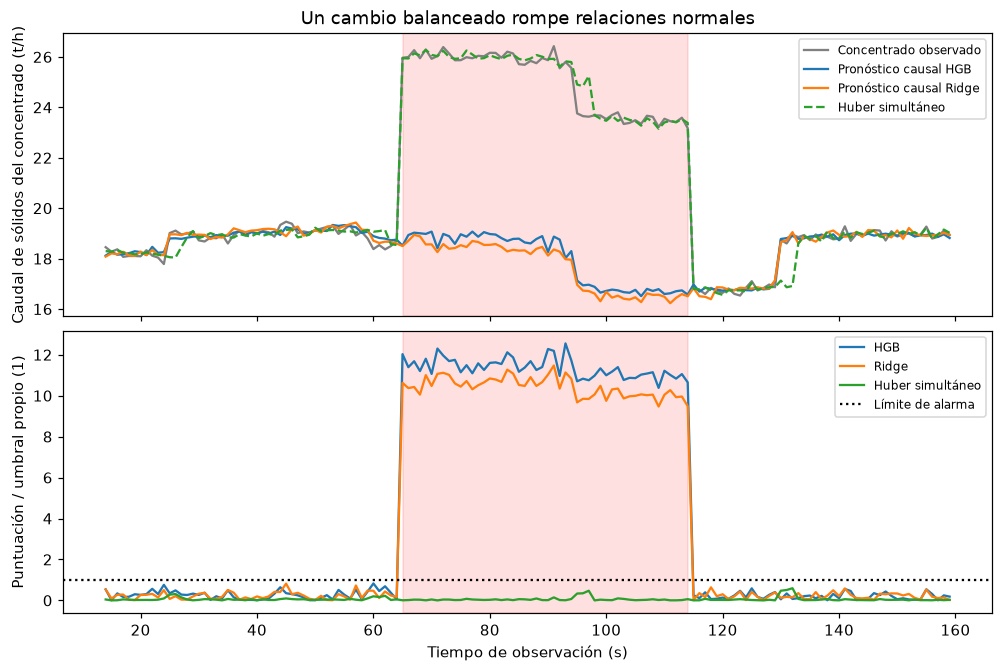

In [10]:
# Mostrar las mismas observaciones de concentrado, tres predicciones o estimaciones y sus puntuaciones calibradas.
time_s = np.arange(14, 160)
channel = 6
fig, axes = plt.subplots(2, 1, figsize=(9, 6), layout="constrained", sharex=True)
axes[0].plot(time_s, changed_relation.observed[14:, channel], color="grey", label="Concentrado observado")
axes[0].plot(time_s, forecast[:, channel], color="tab:blue", label="Pronóstico causal HGB")
axes[0].plot(time_s, ridge_forecast[:, channel], color="tab:orange", label="Pronóstico causal Ridge")
axes[0].plot(time_s, robust_state[:, channel], color="tab:green", linestyle="--", label="Huber simultáneo")
axes[0].set(title="Un cambio balanceado rompe relaciones normales", ylabel="Caudal de sólidos del concentrado (t/h)")
axes[1].plot(time_s, forecast_score[:, channel], color="tab:blue", label="HGB")
axes[1].plot(time_s, ridge_score[:, channel], color="tab:orange", label="Ridge")
axes[1].plot(time_s, robust_score[:, channel] / robust_threshold[channel], color="tab:green", label="Huber simultáneo")
axes[1].axhline(1, color="black", linestyle=":", label="Límite de alarma")
axes[1].set(xlabel="Tiempo de observación (s)", ylabel="Puntuación / umbral propio (1)")
for axis in axes:
    axis.axvspan(65, 114, alpha=0.12, color="red")
    axis.legend(fontsize=8)
plt.show()

Los pronósticos responden a la nueva relación del concentrado según la familia de funciones ajustada,
mientras un estado Huber compatible con conservación puede seguir cerca de la observación cambiada. El panel
inferior separa sorpresa temporal y corrección necesaria para cerrar un balance. Aquí ambos pronósticos de
concentrado siguen cerca de la relación normal mientras la lectura aumenta, manteniendo puntuaciones muy superiores
a uno. Coincidir en ese canal no garantiza el mismo comportamiento de alertas en el resto de la red.
El intervalo rojo muestra verdad solo para interpretar.
Una puntuación predictiva mayor no identifica
por sí sola si cambió el proceso, el instrumento o la relación fija.

Agregamos un sesgo directo de alimentación y un control sano sin cambiar modelos ni umbrales. Conservar solo
el ejemplo de recuperación ocultaría la carga de alertas. La precisión es indefinida sin alarmas y la
sensibilidad es indefinida sin fallas. El cálculo de confusión importado devuelve un valor nulo en esos
casos; lo conservamos, sin presentar la sensibilidad del control sano como perfecta ni como cero.

In [11]:
# Conservar los controles reservados y todas las falsas alarmas de la comparación.
comparisons = {"engine": {"HGB": forecast_metrics, "Ridge": ridge_metrics, "Huber": robust_metrics}}
for family in ["bias", "healthy"]:
    case = generate(family, seed=1000, severity=2)
    predicted = forecast_scores(bundle, case.observed)[14:]
    ridge_predicted = forecast_scores(ridge_bundle, case.observed)[14:]
    projected, _, _ = batch_projection(case.observed[14:], sigma, matrix, robust=True)
    comparisons[family] = {
        "HGB": confusion(predicted > 1, case.fault[14:]),
        "Ridge": confusion(ridge_predicted > 1, case.fault[14:]),
        "Huber": confusion(projected > robust_threshold, case.fault[14:]),
    }
family_names = {"engine": "Cambio de recuperación", "bias": "Sesgo de alimentación", "healthy": "Control sano"}
for family, methods in comparisons.items():
    for method, metrics in methods.items():
        recall_text = "nulo (indefinido)" if metrics["recall"] is None else f"{metrics['recall']:.6f}"
        print(f"{family_names[family]} / {method}: sensibilidad={recall_text}; "
              f"VP={metrics['tp']}; FN={metrics['fn']}; falsas alarmas={metrics['fp']}")

Cambio de recuperación / HGB: sensibilidad=0.970000; VP=291; FN=9; falsas alarmas=19
Cambio de recuperación / Ridge: sensibilidad=0.986667; VP=296; FN=4; falsas alarmas=165
Cambio de recuperación / Huber: sensibilidad=0.000000; VP=0; FN=300; falsas alarmas=4
Sesgo de alimentación / HGB: sensibilidad=1.000000; VP=50; FN=0; falsas alarmas=62
Sesgo de alimentación / Ridge: sensibilidad=1.000000; VP=50; FN=0; falsas alarmas=67
Sesgo de alimentación / Huber: sensibilidad=0.700000; VP=35; FN=15; falsas alarmas=4
Control sano / HGB: sensibilidad=nulo (indefinido); VP=0; FN=0; falsas alarmas=9
Control sano / Ridge: sensibilidad=nulo (indefinido); VP=0; FN=0; falsas alarmas=10
Control sano / Huber: sensibilidad=nulo (indefinido); VP=0; FN=0; falsas alarmas=4


Comparamos sensibilidad solo donde existe un denominador de perturbación y mostramos tasas de falsos
positivos para los tres casos. Ambos paneles usan porcentajes, pero sus denominadores difieren: entradas
canal-tiempo afectadas para sensibilidad y entradas sanas para falsos positivos. Contar eventos en vez de
puntos respondería otra pregunta. Son pocos casos para explicar mecanismos, no para estimar un intervalo
de confianza de una flota industrial ni afirmar superioridad general.

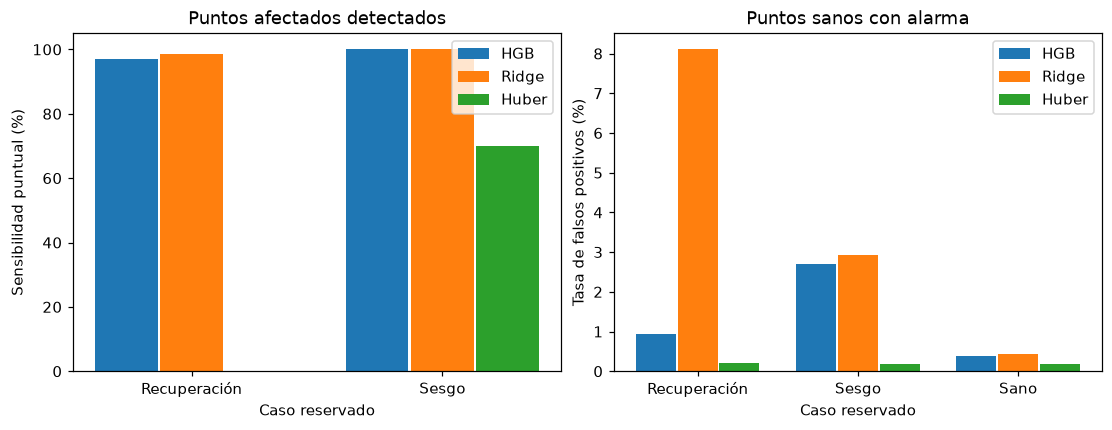

In [12]:
# Mostrar las ganancias de detección y los costos de alertas con sus denominadores distintos.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for offset, method in [(-0.26, "HGB"), (0.0, "Ridge"), (0.26, "Huber")]:
    recalls = [100 * comparisons[f][method]["recall"] for f in ["engine", "bias"]]
    false_rates = [100 * comparisons[f][method]["false_positive_rate"] for f in comparisons]
    axes[0].bar(np.arange(2) + offset, recalls, 0.25, label=method)
    axes[1].bar(np.arange(3) + offset, false_rates, 0.25, label=method)
axes[0].set_xticks([0, 1], ["Recuperación", "Sesgo"])
axes[1].set_xticks([0, 1, 2], ["Recuperación", "Sesgo", "Sano"])
axes[0].set(title="Puntos afectados detectados", ylabel="Sensibilidad puntual (%)", xlabel="Caso reservado")
axes[1].set(title="Puntos sanos con alarma", ylabel="Tasa de falsos positivos (%)", xlabel="Caso reservado")
for axis in axes:
    axis.legend()
plt.show()

Ridge detecta 296 puntos afectados en recuperación frente a 291 de HGB, pero genera 165 falsas alertas frente
a 19. Cinco detecciones adicionales acompañan 146 alertas adicionales sobre entradas sanas. El control sano
tiene diez alertas Ridge y nueve HGB; una secuencia de control no certifica su calibración. Para ubicar el
costo mayor del caso de recuperación descomponemos las falsas alertas por canal y dividimos cada conteo por
sus entradas no afectadas, porque los canales afectados y sanos tienen denominadores elegibles distintos.

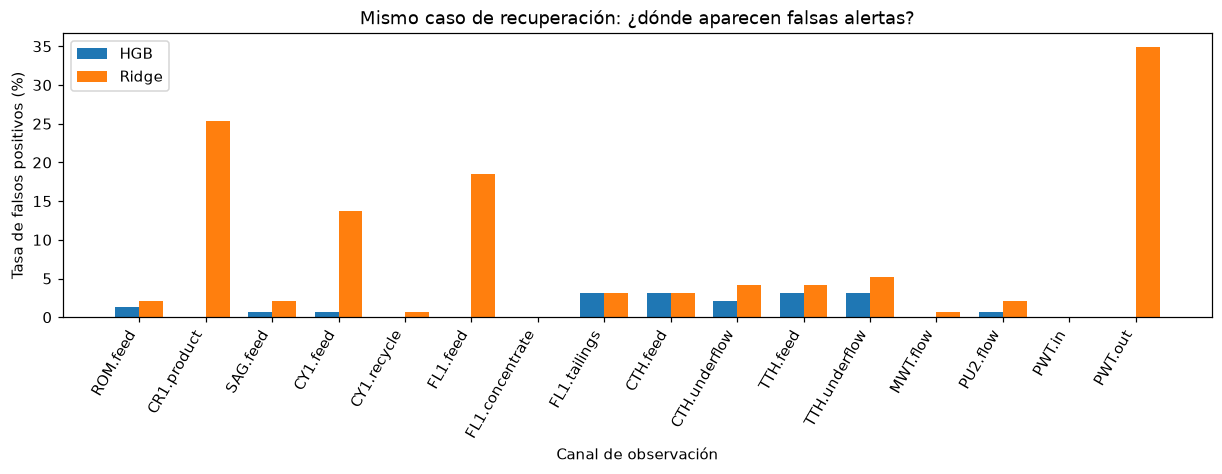

Detecciones Ridge adicionales: 5; falsas alertas adicionales: 146
PWT.out: Ridge=51, HGB=0, entradas no afectadas=146
CR1.product: Ridge=37, HGB=0, entradas no afectadas=146
FL1.feed: Ridge=27, HGB=0, entradas no afectadas=146
CY1.feed: Ridge=20, HGB=1, entradas no afectadas=146


In [13]:
# Ubicar la carga de falsas alertas sobre las mismas entradas canal-tiempo no afectadas.
eligible = (~truth).sum(axis=0)
hgb_false = ((forecast_score > 1) & ~truth).sum(axis=0)
ridge_false = ((ridge_score > 1) & ~truth).sum(axis=0)
positions = np.arange(16)
fig, axis = plt.subplots(figsize=(11, 4.2), layout="constrained")
axis.bar(positions - 0.18, 100 * hgb_false / eligible, 0.36, label="HGB")
axis.bar(positions + 0.18, 100 * ridge_false / eligible, 0.36, label="Ridge")
axis.set_xticks(positions, [s["id"] for s in specs], rotation=60, ha="right")
axis.set(title="Mismo caso de recuperación: ¿dónde aparecen falsas alertas?",
         xlabel="Canal de observación", ylabel="Tasa de falsos positivos (%)")
axis.legend()
plt.show()
extra_detections = ridge_metrics["tp"] - forecast_metrics["tp"]
extra_alerts = ridge_metrics["fp"] - forecast_metrics["fp"]
print(f"Detecciones Ridge adicionales: {extra_detections}; falsas alertas adicionales: {extra_alerts}")
for j in np.argsort(ridge_false)[-4:][::-1]:
    print(f"{specs[j]['id']}: Ridge={ridge_false[j]}, HGB={hgb_false[j]}, entradas no afectadas={eligible[j]}")

Ridge genera 51 falsas alertas en la salida del estanque (`PWT.out`) y 37 en el producto del chancador
(`CR1.product`); HGB no genera ninguna en esos canales. Ambos están fuera del cambio de recuperación inyectado.
Las alertas adicionales siguen siendo errores frente a la verdad sintética conocida. Ambas familias reciben
observaciones, ventanas causales y entradas válidas idénticas. Por tanto, una alineación
distinta o una política de rechazo diferente no explican esta discrepancia local. Los coeficientes lineales
hacen plausible que la relación cambiada propague errores entre canales, pero no permiten atribuir cada alerta
a un peso concreto. La sensibilidad alta y su carga de alertas forman un intercambio que debe quedar visible,
sin transformarlo en una ventaja general de la familia lineal.

La predicción de anomalías con grafos ya aprende relaciones entre sensores: [GDN](https://arxiv.org/abs/2106.06947)
es un antecedente pertinente. Aquí no implementamos ni ejecutamos GDN, y no renombramos el predictor por
histogramas como red de grafos. Los componentes publicados ejecutados son los árboles potenciados de
scikit-learn, Ridge y la pérdida de Huber implementada por la proyección robusta de OreBridge. Así una referencia
bibliográfica no se convierte en una comparación experimental que no se hizo.

## Resultados

**Respuesta:** Ambos predictores usan 1568 filas normales de entrenamiento y 784 de calibración. Ante el cambio
balanceado, Ridge detecta 296 de 300 puntos afectados (98,666667%), HGB detecta 291 (97,000000%) y Huber simultáneo
detecta 0. Sus falsas alertas son 165, 19 y 4, respectivamente. Para el sesgo, Ridge y HGB detectan 50 de 50 puntos
y Huber detecta 35 (70,000000%); sus falsas alertas son 67, 62 y 4. En el control sano generan 10, 9 y 4 alertas,
con sensibilidad indefinida. La ganancia local de sensibilidad de Ridge tiene un costo importante de alertas;
no establece superioridad general.

La sorpresa predictiva puede revelar un cambio balanceado porque el entrenamiento agrega estructura
estadística, pero también puede marcar comportamientos sanos desconocidos. Todo este ejercicio usa
observaciones finitas y válidas. Los faltantes, el rechazo por marcas temporales y la compatibilidad del
modelo requieren el tratamiento explícito de la lección final.

## Resumen

Los tres algoritmos codifican conocimientos distintos. Las relaciones lineales y de árboles predicen patrones
normales; Huber restringe ecuaciones de conservación admitidas. Ajustamos, calibramos y ejecutamos los tres
sin entradas futuras ni umbrales obtenidos de prueba, con los mismos valores de prueba ya conocidos. Esta
extensión retrospectiva permite comparar descriptivamente; queda pendiente una evaluación prospectiva nueva. Un cambio balanceado
puede escapar al residuo de conservación incluso cuando este se calcula perfectamente.

## Referencias

- scikit-learn, `HistGradientBoostingRegressor`, versión instalada exacta 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- scikit-learn, `Ridge`, estimador lineal multisalida ajustado, versión 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Deng y Hooi (2021), *Graph Neural Network-Based Anomaly Detection in Multivariate Time Series*,
  antecedente citado, no comparador ejecutado: https://arxiv.org/abs/2106.06947
- Código ejecutado: `data-pipeline/pipeline/model/learning.py` y
  `data-pipeline/pipeline/stages/plant_evaluate.py`; manifiesto canónico: `data/derived/state-model.json`.